# Recycling behaviour at NUS

DBA5101 Group Project 2

| Student name | Student number |
|---|---|
| Aman Raj Mohta | A0356637R |
| Ananya Vikas Gupta | A0226576W |
| Timothy Low | A0218220W |
| Yang Yi | A0194119B |
| Samuel Chan | A0355925U |

This notebook studies the first recycling trial. We compare the changes at UTOWN with the changes at ENGINE for paper, plastic and cans. We use the difference-in-differences method, or DiD, from Lecture 5.

We begin with the recorded data, examine the baseline, calculate the comparisons and then check how they change under different date choices. The report uses the tables and figures saved by this notebook.

Place `GP2Data.xls` next to this notebook and run all cells in order. The notebook only reads the workbook and never changes it.

## 1. Question and course method

The question is whether the bin openings in Phase 2 and the banners in Phase 3 were associated with lower contamination at UTOWN relative to ENGINE. Contamination is the percentage of incorrectly placed items. A lower value is better.

UTOWN received the changes. ENGINE kept standard bins. In Phase 3, the openings were removed and banners were installed. The supplied data describe areas and dates, rather than individual bins or people.

For each material and intervention, our null hypothesis is that the DiD is zero. We use a two-sided alternative, because the observed comparison could go in either direction. A negative DiD is a relative reduction in contamination. Its unit is **percentage points**, abbreviated pp.

The main assumption is parallel trends: without the intervention, the two areas would have changed by the same amount. Their starting levels can differ. We can inspect the earlier data, but we cannot observe what UTOWN would have done without the intervention.

Course sources: Lecture 5, slides 7-16 and 25; Basic Statistics, slides 33-41 and 54-61. We use the ordinary regression shown in class. Its confidence intervals depend on assumptions about the errors. They do not establish a causal effect on their own.

## 2. Set up the analysis

We load all packages here and set the input and output paths. Dates and choices are kept in one place so that they are easy to check. Figures use the same colours and line styles for each area.

In [1]:
%matplotlib inline

import hashlib
import json
import platform
import warnings
from pathlib import Path

import matplotlib
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels
import statsmodels.formula.api as smf
from IPython.display import Markdown, display
from scipy.stats import norm
from scipy.stats import t as t_dist

# Run the notebook from this repository folder.
notebook_folder = Path.cwd()
data_path = notebook_folder / "GP2Data.xls"
assert data_path.exists(), "Place GP2Data.xls next to this notebook."

# Tables and figures used by the report are written here.
assets_folder = notebook_folder / "assets"
assets_folder.mkdir(exist_ok=True)

# UTOWN received the changes and ENGINE is the comparison area.
AREAS = ["UTOWN", "ENGINE"]
material_columns = {"Paper": "paper_pct", "Plastic": "plastic_pct", "Cans": "can_pct"}
# Phase 1 is the baseline, Phase 2 had the reshaped openings and Phase 3 had the banners.
phase_dates = {
    1: (pd.Timestamp("2020-01-13"), pd.Timestamp("2020-02-10")),
    2: (pd.Timestamp("2020-02-11"), pd.Timestamp("2020-02-22")),
    3: (pd.Timestamp("2020-03-04"), pd.Timestamp("2020-03-17")),
}
# 27 January is the placebo date and the start of the recent baseline.
baseline_split = pd.Timestamp("2020-01-27")
recess_start = pd.Timestamp("2020-02-22")
recess_end = pd.Timestamp("2020-03-01")

# Each area keeps the same colour, line style and marker in every figure.
area_colours = {"UTOWN": "#245B85", "ENGINE": "#A46629"}
area_styles = {"UTOWN": "-", "ENGINE": "--"}
area_markers = {"UTOWN": "o", "ENGINE": "s"}

# These settings apply to every figure and displayed table.
plt.rcParams.update({
    "font.size": 10, "axes.titlesize": 11, "axes.labelsize": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.unicode_minus": False, "figure.dpi": 120,
    "savefig.dpi": 180, "pdf.fonttype": 42,
})
pd.set_option("display.max_columns", 12)
pd.set_option("display.width", 120)
pd.set_option("display.float_format", lambda value: f"{value:.2f}")

# Fingerprint the input. The same check at the end shows the file was not changed.
input_hash = hashlib.sha256(data_path.read_bytes()).hexdigest()
print("Input:", data_path.name)
print("SHA-256:", input_hash)

Input: GP2Data.xls
SHA-256: acade397edbd242b23e434df618e73112afc3dbae85d128bafa72fc022078293


### Helper functions

These four small functions are used throughout. `to_long` turns one row per date into one row per area and date, `fit_did_regression` fits the Lecture 5 interaction model, and the last two keep the figures consistent.

In [2]:
# Turn one row per date, with UTOWN and ENGINE columns, into one row per area and date.
def to_long(wide_data):
    return wide_data.melt(id_vars=["date", "phase"], value_vars=AREAS,
                          var_name="area", value_name="contamination")


# Fit contamination ~ treated + after + treated:after by ordinary least squares.
# The after argument marks the rows in the later period, and the interaction is the DiD.
def fit_did_regression(long_data, after):
    model_data = long_data.assign(
        treated=(long_data["area"] == "UTOWN").astype(int),
        after=after.astype(int),
    )
    return smf.ols("contamination ~ treated + after + treated:after", data=model_data).fit()


# Place date ticks and label them in the form 27 Jan.
def format_date_axis(axis, tick_dates):
    axis.set_xticks(pd.to_datetime(tick_dates))
    axis.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))


# Save a figure as a PDF for the report and as a PNG for quick viewing.
def save_figure(figure, name):
    for extension in ["pdf", "png"]:
        figure.savefig(assets_folder / f"{name}.{extension}", bbox_inches="tight")

## 3. Read the original workbook

We read the shared Excel file directly. Blank padding rows are counted before they are removed. A blank row is different from a missing contamination value within an otherwise recorded observation.

In [3]:
raw_data = pd.read_excel(data_path, engine="xlrd")

# The sheet is padded with completely empty rows. Count them before removing them.
blank_rows = raw_data.isna().all(axis=1)
print("Rows read:", len(raw_data))
print("Completely blank rows:", int(blank_rows.sum()))
display(raw_data.loc[~blank_rows].head())

Rows read: 255
Completely blank rows: 170


,Area,Date,PaperContaminant,PlasticContaminant,CanContaminant,FirstTrialPhase
2,ENGINE,2020-01-15,0.71,35.34,0.87,1.00
5,ENGINE,2020-01-16,1.14,43.93,17.17,1.00
8,ENGINE,2020-01-17,1.29,50.48,29.05,1.00
11,ENGINE,2020-01-18,1.71,47.21,12.22,1.00
14,ENGINE,2020-01-19,0.29,44.44,0.00,1.00


## 4. Prepare the data and check the records

We use descriptive column names, sort dates and keep missing values missing. We check the area-date key, phase dates and percentage scale. Zeros remain recorded zeros.

The recorded paper and plastic rates are zero in both areas on 2 February, while both can values are missing. UTOWN also has identical recorded values on 12 and 16 March. These records are flagged for a later check. We do not know whether they are errors, so the main analysis keeps them.

In [4]:
column_names = {
    "Area": "area", "Date": "date", "FirstTrialPhase": "phase",
    "PaperContaminant": "paper_pct", "PlasticContaminant": "plastic_pct",
    "CanContaminant": "can_pct",
}
clean_data = (
    raw_data.loc[~blank_rows]
    .rename(columns=column_names)
    .assign(date=lambda data: pd.to_datetime(data["date"], errors="raise"),
            phase=lambda data: data["phase"].astype(int))
    .sort_values(["date", "area"])
    .reset_index(drop=True)
)
clean_data["weekend"] = clean_data["date"].dt.dayofweek >= 5
clean_data["recess"] = clean_data["date"].between(recess_start, recess_end)

# Check that the keys are complete, each area has one record per date and each date
# sits inside exactly one phase. Every reading must be a percentage.
assert not clean_data[["area", "date", "phase"]].isna().any().any()
assert not clean_data.duplicated(["area", "date"]).any()
assert set(clean_data["area"]) == set(AREAS)
assert set(clean_data["phase"]) == {1, 2, 3}
assert clean_data.groupby("date")["phase"].nunique().max() == 1
for phase, (start_date, end_date) in phase_dates.items():
    assert clean_data.loc[clean_data["phase"] == phase, "date"].between(start_date, end_date).all()
for column in material_columns.values():
    assert clean_data[column].dropna().between(0, 100).all()

missing_counts = [int(clean_data[column].isna().sum()) for column in material_columns.values()]
audit_table = pd.DataFrame({
    "Check": ["Raw rows", "Blank rows removed", "Area-date records", "Duplicate area-date keys",
              "Missing paper", "Missing plastic", "Missing cans", "Recorded weekend rows"],
    "Count": [len(raw_data), int(blank_rows.sum()), len(clean_data),
              int(clean_data.duplicated(["area", "date"]).sum()),
              *missing_counts, int(clean_data["weekend"].sum())],
})
display(audit_table)

# Flag 2 February and UTOWN's identical 12 and 16 March records for the later checks.
is_2_february = clean_data["date"] == "2020-02-02"
is_utown_march_repeat = (
    (clean_data["area"] == "UTOWN")
    & clean_data["date"].isin(pd.to_datetime(["2020-03-12", "2020-03-16"]))
)
flagged_rows = clean_data.loc[
    is_2_february | is_utown_march_repeat,
    ["date", "area", "phase", "paper_pct", "plastic_pct", "can_pct"],
]
display(flagged_rows)

,Check,Count
0,Raw rows,255
1,Blank rows removed,170
2,Area-date records,85
3,Duplicate area-date keys,0
4,Missing paper,0
5,Missing plastic,0
6,Missing cans,2
7,Recorded weekend rows,16


,date,area,phase,paper_pct,plastic_pct,can_pct
27,2020-02-02,ENGINE,1,0.00,0.00,NaN
28,2020-02-02,UTOWN,1,0.00,0.00,NaN
76,2020-03-12,UTOWN,3,6.89,55.66,26.18
82,2020-03-16,UTOWN,3,6.89,55.66,26.18


The case describes weekday collection, but the workbook contains weekend dates. We retain the recorded dates and later repeat the comparison using weekdays only. We do not fill the gap between the second and third phases.

## 5. Summarise the recorded data

These means use all available non-missing readings. They help us check the input against Exhibit 5 of the case. They are not yet the means used for the main matched-date DiD.

Each observed day receives equal weight. The file does not give item counts or waste volumes. Therefore, these are average daily percentages, not a pooled percentage of all items collected.

In [5]:
# Average each area in each phase, using every recorded reading.
area_phase_summary = clean_data.groupby(["phase", "area"]).agg(
    recorded_dates=("date", "size"),
    paper_mean=("paper_pct", "mean"),
    plastic_mean=("plastic_pct", "mean"),
    can_mean=("can_pct", "mean"),
    valid_can_dates=("can_pct", "count"),
).reset_index()
display(area_phase_summary)

# These rounded means are transcribed from Exhibit 5 of the case as an input check.
case_means = pd.DataFrame([
    [1, "ENGINE", 0.81, 45.94, 14.85], [1, "UTOWN", 6.04, 57.28, 36.47],
    [2, "ENGINE", 1.29, 35.96, 11.67], [2, "UTOWN", 4.00, 46.51, 18.34],
    [3, "ENGINE", 0.75, 40.88, 7.55], [3, "UTOWN", 4.69, 59.18, 22.31],
], columns=["phase", "area", "paper_mean", "plastic_mean", "can_mean"])
case_check = area_phase_summary.merge(case_means, on=["phase", "area"],
                                      suffixes=("_data", "_case"))
for material in ["paper", "plastic", "can"]:
    difference = case_check[f"{material}_mean_data"] - case_check[f"{material}_mean_case"]
    assert difference.abs().max() < 0.0051
print("The computed means agree with Exhibit 5 to its displayed precision.")

,phase,area,recorded_dates,paper_mean,plastic_mean,can_mean,valid_can_dates
0,1,ENGINE,20,0.81,45.94,14.85,19
1,1,UTOWN,20,6.04,57.28,36.47,19
2,2,ENGINE,11,1.29,35.96,11.67,11
3,2,UTOWN,11,4.00,46.51,18.34,11
4,3,ENGINE,12,0.75,40.88,7.55,12
5,3,UTOWN,11,4.69,59.18,22.31,11


The computed means agree with Exhibit 5 to its displayed precision.


## 6. Select the same dates at both locations

We match dates separately for each material. A date is used only when both locations have a valid reading for that material. A January date is compared with the same January date at the other location. We do not pair January with March.

This restriction helps align calendar conditions. It cannot make the two populations identical or remove a calendar change that affects them differently. The all-readings version is retained as a later sensitivity check.

In [6]:
# For each material, keep one row per date with UTOWN, ENGINE and their gap.
paired_data = {}
sample_counts = []
unmatched_records = []

for material, column in material_columns.items():
    wide_data = clean_data.pivot(index=["date", "phase"], columns="area", values=column)

    # Note the dates where one area has no reading, then keep only dates with both.
    incomplete_dates = wide_data[wide_data[AREAS].isna().any(axis=1)]
    for (date, phase), reading in incomplete_dates.iterrows():
        unmatched_records.append({
            "Material": material, "Date": date.strftime("%d %b"), "Phase": phase,
            "UTOWN available": pd.notna(reading["UTOWN"]),
            "ENGINE available": pd.notna(reading["ENGINE"]),
        })
    matched = wide_data.dropna(subset=AREAS).reset_index().sort_values("date")
    matched["gap"] = matched["UTOWN"] - matched["ENGINE"]
    paired_data[material] = matched

    phase_counts = {f"Phase {phase}": int((matched["phase"] == phase).sum()) for phase in [1, 2, 3]}
    sample_counts.append({"Material": material, **phase_counts})

sample_count_table = pd.DataFrame(sample_counts)
unmatched_table = pd.DataFrame(unmatched_records)
display(sample_count_table)
display(unmatched_table)

,Material,Phase 1,Phase 2,Phase 3
0,Paper,18,11,11
1,Plastic,18,11,11
2,Cans,17,11,11


,Material,Date,Phase,UTOWN available,ENGINE available
0,Paper,13 Jan,1,True,False
1,Paper,14 Jan,1,True,False
2,Paper,16 Jan,1,False,True
3,Paper,07 Feb,1,False,True
4,Paper,10 Mar,3,False,True
5,Plastic,13 Jan,1,True,False
6,Plastic,14 Jan,1,True,False
7,Plastic,16 Jan,1,False,True
8,Plastic,07 Feb,1,False,True
9,Plastic,10 Mar,3,False,True


## 7. Plot the observations across the three phases

The dots are recorded values in the matched samples. Lines join observations within each phase as a reading aid. Missing dates are not filled. Each material has its own vertical scale, labelled in percent.

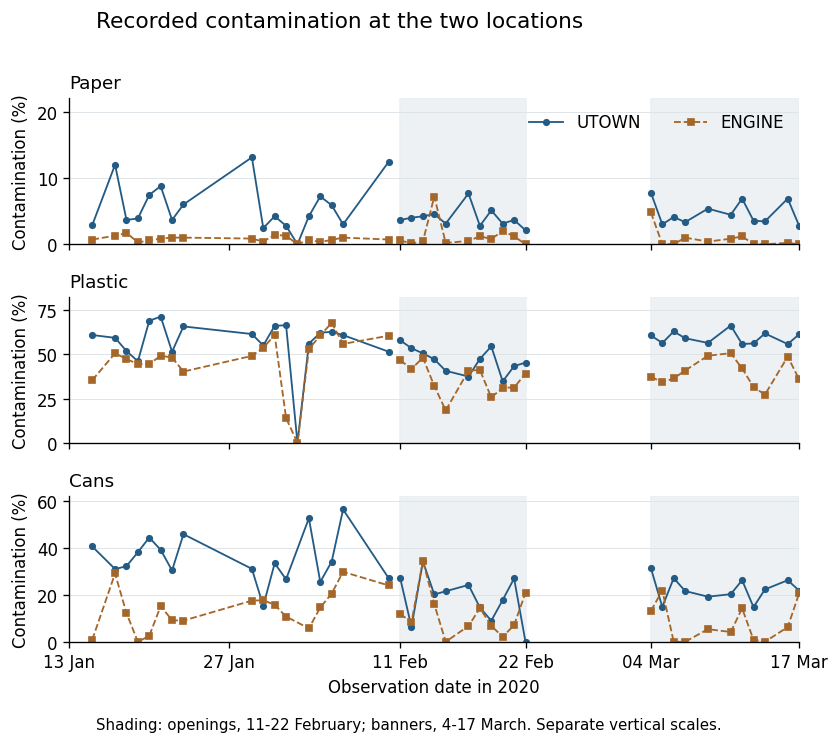

In [7]:
figure, axes = plt.subplots(3, 1, figsize=(7.1, 6.2), sharex=True)

for axis, (material, matched) in zip(axes, paired_data.items()):
    # Draw each phase separately so that no line bridges the gaps between phases.
    for area in AREAS:
        for phase in [1, 2, 3]:
            phase_data = matched[matched["phase"] == phase]
            axis.plot(phase_data["date"], phase_data[area], area_styles[area],
                      marker=area_markers[area], markersize=3.3, linewidth=1.1,
                      color=area_colours[area], label=area if phase == 1 else None)

    # Shade the openings and banners periods.
    for start_date, end_date in [phase_dates[2], phase_dates[3]]:
        axis.axvspan(start_date, end_date, color="#E9EEF2", alpha=0.8, zorder=0)

    axis.set_title(material, loc="left")
    axis.set_ylabel("Contamination (%)")
    axis.set_ylim(0, np.ceil(matched[AREAS].max().max() / 10) * 10 + 2)
    axis.grid(axis="y", color="#DFE4E8", linewidth=0.6)

axes[0].legend(ncol=2, loc="upper right", frameon=False)
format_date_axis(axes[-1], ["2020-01-13", "2020-01-27", "2020-02-11",
                            "2020-02-22", "2020-03-04", "2020-03-17"])
axes[-1].set_xlim(pd.Timestamp("2020-01-13"), pd.Timestamp("2020-03-17"))
axes[-1].set_xlabel("Observation date in 2020")
figure.suptitle("Recorded contamination at the two locations", x=0.12, ha="left", fontsize=13)
figure.text(0.12, 0.015, "Shading: openings, 11-22 February; banners, 4-17 March. "
            "Separate vertical scales.", fontsize=9)
figure.tight_layout(rect=[0, 0.035, 1, 0.97])
save_figure(figure, "daily_trends")
plt.show()

The locations have different contamination levels. That difference alone does not rule out DiD. We need to examine whether their changes were similar before the interventions. The plot also reminds us that a fall at UTOWN can occur alongside a fall at ENGINE.

## 8. Examine the baseline gap

The daily gap is UTOWN minus ENGINE. A roughly stable gap before intervention is more reassuring than a gap that is already moving. We fit a simple line to describe its movement, using the regression ideas from Basic Statistics. The line does not predict a corrected treatment effect.

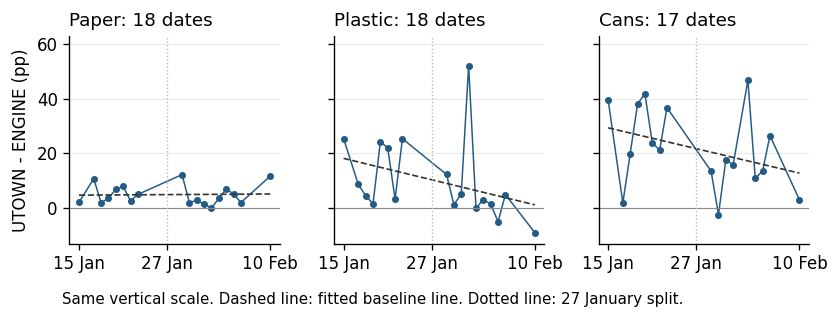

In [8]:
# Take the Phase 1 rows of each matched sample and count the days from 13 January.
baseline_data = {}
baseline_models = {}
for material, matched in paired_data.items():
    baseline = matched[matched["phase"] == 1].copy()
    baseline["day"] = (baseline["date"] - phase_dates[1][0]).dt.days
    baseline_data[material] = baseline
    baseline_models[material] = smf.ols("gap ~ day", data=baseline).fit()

# Use one vertical scale for all three panels, rounded out to the nearest 10 pp.
all_baseline_gaps = pd.concat([baseline["gap"] for baseline in baseline_data.values()])
gap_minimum = np.floor(min(0, all_baseline_gaps.min()) / 10) * 10 - 3
gap_maximum = np.ceil(all_baseline_gaps.max() / 10) * 10 + 3

figure, axes = plt.subplots(1, 3, figsize=(7.1, 2.65), sharey=True)
for axis, (material, baseline) in zip(axes, baseline_data.items()):
    fitted_line = baseline_models[material].predict(baseline)
    axis.plot(baseline["date"], baseline["gap"], "o-", color="#245B85",
              linewidth=0.9, markersize=3.2)
    axis.plot(baseline["date"], fitted_line, "--", color="#333333", linewidth=1)
    axis.axhline(0, color="#8A8A8A", linewidth=0.7)
    axis.axvline(baseline_split, color="#B5B5B5", linestyle=":", linewidth=0.8)
    axis.set_title(f"{material}: {len(baseline)} dates", loc="left")
    format_date_axis(axis, ["2020-01-15", "2020-01-27", "2020-02-10"])
    axis.set_ylim(gap_minimum, gap_maximum)
    axis.grid(axis="y", color="#E2E6E9", linewidth=0.5)

axes[0].set_ylabel("UTOWN - ENGINE (pp)")
figure.text(0.08, 0.025, "Same vertical scale. Dashed line: fitted baseline line. "
            "Dotted line: 27 January split.", fontsize=9)
figure.tight_layout(rect=[0, 0.065, 1, 1])
save_figure(figure, "baseline_gaps")
plt.show()

## 9. Describe baseline movement and run a placebo comparison

Lecture 5, slide 14, discusses pre-intervention trend checks and placebo DiD. We describe the fitted gap change per week. We also pretend that the intervention began on 27 January, within Phase 1. This calendar split was used in the earlier work. No bins changed on that date in the supplied trial.

Both checks use only baseline observations. A large p-value means that this short sample does not clearly distinguish the estimate from zero under the model assumptions. It does not establish parallel trends.

In [9]:
baseline_rows = []
for material, baseline in baseline_data.items():
    # The trend is the fitted change in the daily gap, converted from per day to per week.
    trend_model = baseline_models[material]
    trend_interval = trend_model.conf_int().loc["day"] * 7

    # The placebo runs the DiD regression within Phase 1, as if a change began on 27 January.
    baseline_long = to_long(baseline)
    placebo_model = fit_did_regression(baseline_long,
                                       after=baseline_long["date"] >= baseline_split)

    baseline_rows.append({
        "material": material,
        "dates": len(baseline),
        "gap_change_per_week": trend_model.params["day"] * 7,
        "trend_ci_low": trend_interval.iloc[0],
        "trend_ci_high": trend_interval.iloc[1],
        "trend_p": trend_model.pvalues["day"],
        "placebo_did": placebo_model.params["treated:after"],
        "placebo_p": placebo_model.pvalues["treated:after"],
    })
baseline_results = pd.DataFrame(baseline_rows)

baseline_display = baseline_results[["material", "dates", "gap_change_per_week",
                                     "trend_p", "placebo_did", "placebo_p"]].copy()
for column in ["trend_p", "placebo_p"]:
    baseline_display[column] = baseline_display[column].map(lambda value: f"{value:.3f}")
display(baseline_display)

weekly_change = baseline_results.set_index("material")["gap_change_per_week"]
baseline_lookup = baseline_results.set_index("material")
display(Markdown(
    f"The fitted gap changes are {weekly_change['Paper']:+.2f} pp per week for paper, "
    f"{weekly_change['Plastic']:+.2f} for plastic and {weekly_change['Cans']:+.2f} for cans. "
    "Paper is steadier in this summary. The earlier narrowing for plastic and cans gives us "
    "reason to be cautious about their later DiD estimates."
))

,material,dates,gap_change_per_week,trend_p,placebo_did,placebo_p
0,Paper,18,0.11,0.892,-0.32,0.865
1,Plastic,18,-4.58,0.147,-7.76,0.486
2,Cans,17,-4.46,0.168,-11.74,0.079


The fitted gap changes are +0.11 pp per week for paper, -4.58 for plastic and -4.46 for cans. Paper is steadier in this summary. The earlier narrowing for plastic and cans gives us reason to be cautious about their later DiD estimates.

## 10. Write the DiD calculation

We first calculate each location's change from the baseline. We then subtract ENGINE's change from UTOWN's change:

\[
\text{DiD}=(\bar Y_{U,\,after}-\bar Y_{U,\,before})-(\bar Y_{E,\,after}-\bar Y_{E,\,before}).
\]

Here, a bar means an average over the selected dates. U denotes UTOWN and E denotes ENGINE. The function below follows these four means directly. All means in a comparison use the same selected sample as its DiD.

In [10]:
# Calculate the DiD from four averages, as the change at UTOWN minus the change at ENGINE.
# The input has one row per area and date, with a contamination column.
def calculate_changes(selected_data, before_phase, after_phase):
    def readings(phase, area):
        rows = (selected_data["phase"] == phase) & (selected_data["area"] == area)
        return selected_data.loc[rows, "contamination"]

    utown_before = readings(before_phase, "UTOWN")
    utown_after = readings(after_phase, "UTOWN")
    engine_before = readings(before_phase, "ENGINE")
    engine_after = readings(after_phase, "ENGINE")

    utown_change = utown_after.mean() - utown_before.mean()
    engine_change = engine_after.mean() - engine_before.mean()
    return {
        "utown_before": utown_before.mean(), "utown_after": utown_after.mean(),
        "engine_before": engine_before.mean(), "engine_after": engine_after.mean(),
        "utown_change": utown_change, "engine_change": engine_change,
        "did": utown_change - engine_change,
        "utown_before_n": len(utown_before), "utown_after_n": len(utown_after),
        "engine_before_n": len(engine_before), "engine_after_n": len(engine_after),
    }

## 11. Calculate both interventions against Phase 1

We repeat the calculation for each material. The two comparisons are Phase 2 versus Phase 1 and Phase 3 versus Phase 1. The displayed averages and changes are rounded for reading. The calculations use the unrounded values.

In [11]:
# For each material and compared phase, keep the long data for Phase 1 and that phase.
analysis_samples = {}
arithmetic_rows = []
for phase in [2, 3]:
    for material, matched in paired_data.items():
        selected = matched[matched["phase"].isin([1, phase])]
        selected_long = to_long(selected).sort_values(["date", "area"]).reset_index(drop=True)
        analysis_samples[(material, phase)] = selected_long
        arithmetic_rows.append({"phase": phase, "material": material,
                                **calculate_changes(selected_long, 1, phase)})
arithmetic_results = pd.DataFrame(arithmetic_rows)

mean_columns = ["material", "utown_before", "utown_after", "engine_before", "engine_after", "did"]
for phase in [2, 3]:
    print(f"Phase {phase} compared with Phase 1. Means are percentages; DiD is in pp.")
    display(arithmetic_results.loc[arithmetic_results["phase"] == phase, mean_columns].round(2))

Phase 2 compared with Phase 1. Means are percentages; DiD is in pp.


,material,utown_before,utown_after,engine_before,engine_after,did
0,Paper,5.76,4.00,0.82,1.29,-2.23
1,Plastic,56.41,46.51,46.32,35.96,0.46
2,Cans,35.47,18.34,13.77,11.67,-15.02


Phase 3 compared with Phase 1. Means are percentages; DiD is in pp.


,material,utown_before,utown_after,engine_before,engine_after,did
3,Paper,5.76,4.69,0.82,0.77,-1.01
4,Plastic,56.41,59.18,46.32,39.39,9.69
5,Cans,35.47,22.31,13.77,7.86,-7.24


## 12. Fit the regression taught in class

We use the Lecture 5 interaction model:

\[
Y_{it}=\alpha+\beta\,Treated_i+\gamma\,After_t+
\delta\,(Treated_i\times After_t)+\varepsilon_{it}.
\]

`treated` is 1 for UTOWN and 0 for ENGINE. `after` is 1 in the phase being compared with Phase 1. Both main effects remain in the model. The interaction coefficient, delta, is the DiD.

The intercept is ENGINE's baseline mean. The treatment coefficient is the initial area gap. The after coefficient is ENGINE's change. The interaction is UTOWN's additional change. The error term contains other influences that the model does not explain.

We use ordinary least squares, or OLS, as in the class examples. The usual confidence interval relies on independent errors with a common variance and the model's distribution assumptions. These assumptions are uncertain here. The interval does not include bias from a failed parallel-trends assumption, and repeated days do not create additional treatment areas.

In [12]:
fitted_models = {}
regression_rows = []
for (material, phase), selected in analysis_samples.items():
    model = fit_did_regression(selected, after=selected["phase"] == phase)
    fitted_models[(material, phase)] = model
    ci_low, ci_high = model.conf_int().loc["treated:after"]
    regression_rows.append({
        "phase": phase, "material": material,
        "did": model.params["treated:after"],
        "ci_low": ci_low, "ci_high": ci_high,
        "p_value": model.pvalues["treated:after"],
        "area_date_rows": int(model.nobs),
    })
regression_results = pd.DataFrame(regression_rows)

# The interaction coefficient must equal the four-mean DiD from the previous step.
agreement_check = arithmetic_results.merge(regression_results, on=["material", "phase"],
                                           suffixes=("_means", "_ols"))
np.testing.assert_allclose(agreement_check["did_means"], agreement_check["did_ols"], atol=1e-10)

regression_display = regression_results.copy()
regression_display["p_value"] = regression_display["p_value"].map(lambda value: f"{value:.3f}")
display(regression_display)
print("The interaction coefficients agree with the four-mean calculations.")

# Build the full coefficient table for cans in the openings period, shown in report Table 7.
can_model = fitted_models[("Cans", 2)]
coefficient_table = pd.DataFrame({
    "Term": ["Intercept", "UTOWN", "After", "UTOWN x After"],
    "Coefficient": can_model.params.values,
    "Standard error": can_model.bse.values,
    "p-value": can_model.pvalues.values,
})
coefficient_display = coefficient_table.copy()
coefficient_display["p-value"] = coefficient_display["p-value"].map(lambda value: f"{value:.3f}")
display(coefficient_display)

,phase,material,did,ci_low,ci_high,p_value,area_date_rows
0,2,Paper,-2.23,-4.81,0.34,0.088,58
1,2,Plastic,0.46,-14.40,15.31,0.951,58
2,2,Cans,-15.02,-25.73,-4.32,0.007,56
3,3,Paper,-1.01,-3.54,1.51,0.424,58
4,3,Plastic,9.69,-4.68,24.07,0.182,58
5,3,Cans,-7.24,-16.78,2.29,0.133,56


The interaction coefficients agree with the four-mean calculations.


,Term,Coefficient,Standard error,p-value
0,Intercept,13.77,2.37,0.000
1,UTOWN,21.69,3.34,0.000
2,After,-2.10,3.77,0.581
3,UTOWN x After,-15.02,5.34,0.007


## 13. Read one result step by step

The following explanation is built from the executed results. It separates the observed change at UTOWN from its change relative to ENGINE. A larger relative fall does not by itself establish why that fall occurred.

In [13]:
main_lookup = arithmetic_results.set_index(["phase", "material"])
can_openings = main_lookup.loc[(2, "Cans")]
plastic_openings = main_lookup.loc[(2, "Plastic")]

display(Markdown(
    f"**Cans in Phase 2.** UTOWN's mean moved from {can_openings.utown_before:.2f}% to "
    f"{can_openings.utown_after:.2f}%. ENGINE's mean moved from "
    f"{can_openings.engine_before:.2f}% to {can_openings.engine_after:.2f}%. "
    f"Using the unrounded means, the changes were {can_openings.utown_change:.2f} pp and "
    f"{can_openings.engine_change:.2f} pp. Their difference is {can_openings.did:.2f} pp. "
    "This is an observed relative fall. The earlier can-gap movement and possible calendar "
    "effects limit its causal interpretation.\n\n"
    f"**Plastic in Phase 2.** UTOWN changed by {plastic_openings.utown_change:.2f} pp and "
    f"ENGINE by {plastic_openings.engine_change:.2f} pp. Both improved by similar amounts, "
    f"giving a DiD of {plastic_openings.did:+.2f} pp. Looking only at UTOWN would miss this "
    "shared movement."
))

**Cans in Phase 2.** UTOWN's mean moved from 35.47% to 18.34%. ENGINE's mean moved from 13.77% to 11.67%. Using the unrounded means, the changes were -17.12 pp and -2.10 pp. Their difference is -15.02 pp. This is an observed relative fall. The earlier can-gap movement and possible calendar effects limit its causal interpretation.

**Plastic in Phase 2.** UTOWN changed by -9.91 pp and ENGINE by -10.36 pp. Both improved by similar amounts, giving a DiD of +0.46 pp. Looking only at UTOWN would miss this shared movement.

### 13a. Plot both comparisons as a difference-in-differences picture and check the paper result

The report's Figure 2 has one row for Phase 1 against Phase 2 and one row for Phase 1 against Phase 3, so that neither row suggests a three-phase comparison. Each panel plots the average daily contamination of UTOWN and ENGINE on the matched dates. The dashed line shows where UTOWN would have ended if it had moved by the same amount as ENGINE, and the arrow is the estimated effect, which equals the change in the UTOWN - ENGINE gap. The table keeps the average gap in each phase with 95% intervals.

,Material,Phase,Dates,Mean gap,Lower,Upper
0,Paper,1,18,4.94,3.10,6.78
1,Paper,2,11,2.71,1.09,4.32
2,Paper,3,11,3.92,3.02,4.82
3,Plastic,1,18,10.09,2.77,17.42
4,Plastic,2,11,10.55,4.41,16.69
5,Plastic,3,11,19.79,14.14,25.43
6,Cans,1,17,21.69,14.08,29.31
7,Cans,2,11,6.67,-1.86,15.20
8,Cans,3,11,14.45,7.86,21.04


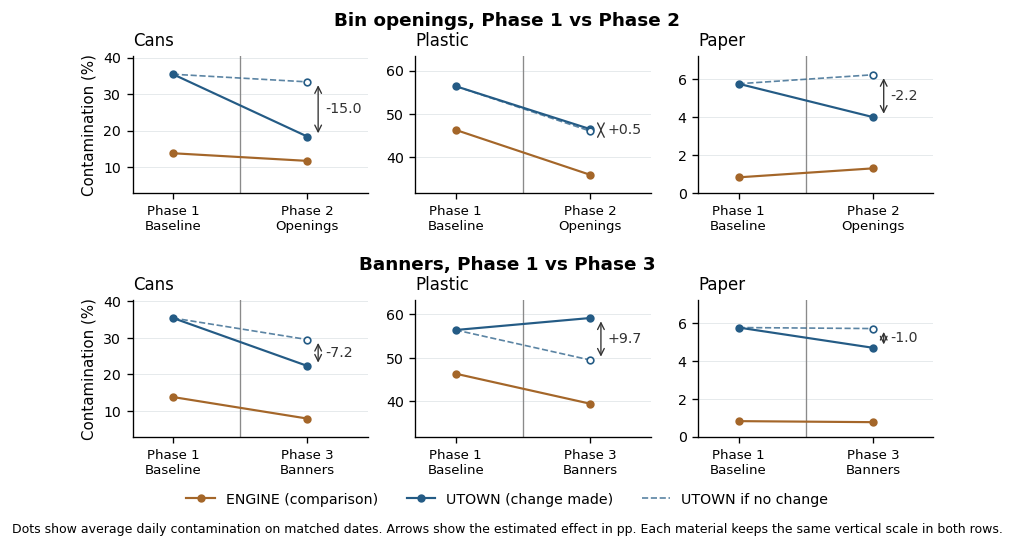

In [14]:
# Calculate the average daily gap in each phase, with a 95% t-interval for that average.
phase_gap_rows = []
for material, matched in paired_data.items():
    for phase in [1, 2, 3]:
        gaps = matched.loc[matched["phase"] == phase, "gap"]
        half_width = t_dist.ppf(0.975, len(gaps) - 1) * gaps.std(ddof=1) / np.sqrt(len(gaps))
        phase_gap_rows.append({"Material": material, "Phase": phase, "Dates": len(gaps),
                               "Mean gap": gaps.mean(),
                               "Lower": gaps.mean() - half_width,
                               "Upper": gaps.mean() + half_width})
phase_gap_table = pd.DataFrame(phase_gap_rows)
display(phase_gap_table)
mean_gap = phase_gap_table.set_index(["Material", "Phase"])["Mean gap"]

# Calculate the average contamination of each area in each phase, on the matched dates.
phase_area_means = {
    (material, phase): matched.loc[matched["phase"] == phase, AREAS].mean()
    for material, matched in paired_data.items() for phase in [1, 2, 3]
}


# Find where UTOWN would be if it had moved by the same amount as ENGINE.
def no_change_level(material, phase):
    before, after = phase_area_means[(material, 1)], phase_area_means[(material, phase)]
    return before["UTOWN"] + after["ENGINE"] - before["ENGINE"]


# Each material keeps one vertical scale across both rows.
panel_limits = {}
for material in paired_data:
    values = [value for phase in [1, 2, 3] for value in phase_area_means[(material, phase)]]
    values += [no_change_level(material, phase) for phase in [2, 3]]
    padding = (max(values) - min(values)) * 0.18
    panel_limits[material] = (max(0, min(values) - padding), max(values) + padding)

phase_labels = {1: "Phase 1\nBaseline", 2: "Phase 2\nOpenings", 3: "Phase 3\nBanners"}
row_titles = {2: "Bin openings, Phase 1 vs Phase 2", 3: "Banners, Phase 1 vs Phase 3"}

figure, grid = plt.subplots(2, 3, figsize=(7.4, 4.6))
for row, phase in zip(grid, [2, 3]):
    for axis, material in zip(row, ["Cans", "Plastic", "Paper"]):
        before, after = phase_area_means[(material, 1)], phase_area_means[(material, phase)]
        counterfactual = no_change_level(material, phase)
        effect = after["UTOWN"] - counterfactual

        # The arrow equals the change in the UTOWN - ENGINE gap, which is the DiD.
        assert abs(effect - (mean_gap[(material, phase)] - mean_gap[(material, 1)])) < 1e-9

        axis.axvline(0.5, color="#8A8A8A", linewidth=0.8)
        axis.plot([0, 1], [before["ENGINE"], after["ENGINE"]], "-o", color=area_colours["ENGINE"],
                  linewidth=1.3, markersize=4, label="ENGINE (comparison)")
        axis.plot([0, 1], [before["UTOWN"], after["UTOWN"]], "-o", color=area_colours["UTOWN"],
                  linewidth=1.3, markersize=4, label="UTOWN (change made)")
        axis.plot([0, 1], [before["UTOWN"], counterfactual], "--", color=area_colours["UTOWN"],
                  linewidth=1.0, alpha=0.75, label="UTOWN if no change")
        axis.plot([1], [counterfactual], "o", markerfacecolor="white",
                  markeredgecolor=area_colours["UTOWN"], markersize=4)
        axis.annotate("", xy=(1.08, after["UTOWN"]), xytext=(1.08, counterfactual),
                      arrowprops=dict(arrowstyle="<->", color="#333333", linewidth=0.8))
        axis.text(1.13, (after["UTOWN"] + counterfactual) / 2, f"{effect:+.1f}",
                  va="center", fontsize=8.5, color="#333333")

        axis.set_title(material, loc="left", fontsize=10)
        axis.set_xticks([0, 1])
        axis.set_xticklabels([phase_labels[1], phase_labels[phase]], fontsize=8)
        axis.set_xlim(-0.3, 1.45)
        axis.set_ylim(*panel_limits[material])
        axis.tick_params(axis="y", labelsize=8.5)
        axis.grid(axis="y", color="#E2E6E9", linewidth=0.5)
    row[0].set_ylabel("Contamination (%)", fontsize=9)

handles, labels = grid[0][0].get_legend_handles_labels()
figure.legend(handles, labels, loc="lower center", ncol=3, frameon=False, fontsize=8.5,
              bbox_to_anchor=(0.5, 0.025))
figure.text(0.5, 0.0, "Dots show average daily contamination on matched dates. Arrows show the "
            "estimated effect in pp. Each material keeps the same vertical scale in both rows.",
            ha="center", fontsize=7.5)
figure.tight_layout(rect=[0, 0.07, 1, 0.94], h_pad=2.6)
for row, phase in zip(grid, [2, 3]):
    figure.text(0.5, row[0].get_position().y1 + 0.055, row_titles[phase],
                ha="center", fontsize=11, fontweight="bold")
save_figure(figure, "did_combined")
plt.show()

The paper check below counts UTOWN's days above 8% in each phase and repeats both paper comparisons without the Phase 1 days above that level.

In [15]:
paper = paired_data["Paper"]
utown_above_8 = paper["UTOWN"] > 8
days_above_8 = {phase: int((utown_above_8 & (paper["phase"] == phase)).sum()) for phase in [1, 2, 3]}
print("UTOWN paper days above 8% by phase:", days_above_8)

high_paper_dates = paper.loc[utown_above_8 & (paper["phase"] == 1), "date"]
paper_without_high = paper[~paper["date"].isin(high_paper_dates)]
for phase in [2, 3]:
    selected = to_long(paper_without_high[paper_without_high["phase"].isin([1, phase])])
    model = fit_did_regression(selected, after=selected["phase"] == phase)
    low, high = model.conf_int().loc["treated:after"]
    print(f"Paper, P{phase} versus P1, without high days: "
          f"DiD {model.params['treated:after']:+.2f} pp, 95% interval [{low:.2f}, {high:.2f}], "
          f"p = {model.pvalues['treated:after']:.3f}")

UTOWN paper days above 8% by phase: {1: 4, 2: 0, 3: 0}
Paper, P2 versus P1, without high days: DiD -0.60 pp, 95% interval [-2.44, 1.24], p = 0.516
Paper, P3 versus P1, without high days: DiD +0.62 pp, 95% interval [-1.12, 2.36], p = 0.478


### 13b. Size a follow-up trial for plastic

The report's conclusion suggests how many collection days each phase of a follow-up trial needs. We use the day-to-day spread of the plastic gap within each phase and the standard two-group sample-size formula with 80% power and a 5% two-sided significance level. This is a planning estimate that assumes similar day-to-day variation in a future trial.

In [16]:
# Pool the day-to-day spread of the plastic gap within each phase.
plastic_gaps = paired_data["Plastic"]
within_phase_sd = np.sqrt(plastic_gaps.groupby("phase")["gap"].var(ddof=1).mean())
print(f"Plastic gap, average within-phase standard deviation: {within_phase_sd:.2f} pp")

# The standard two-group formula gives the days needed in each phase.
z_total = norm.ppf(0.975) + norm.ppf(0.80)
for effect in [10, 5]:
    days_per_phase = 2 * (z_total * within_phase_sd / effect) ** 2
    print(f"Days per phase to detect a {effect} pp change: {days_per_phase:.1f}")

Plastic gap, average within-phase standard deviation: 11.12 pp
Days per phase to detect a 10 pp change: 19.4
Days per phase to detect a 5 pp change: 77.7


## 14. Look at the regression errors

A residual is an observed value minus its fitted value. Basic Statistics, slides 54-58, discusses the assumptions behind regression inference. We plot residuals by date and compare their spread across the four groups in each model.

These plots can show uneven spread or unusual days. They cannot establish independent errors. We therefore treat the ordinary OLS intervals and p-values as conditional model results, rather than sufficient evidence that the interventions caused the changes.

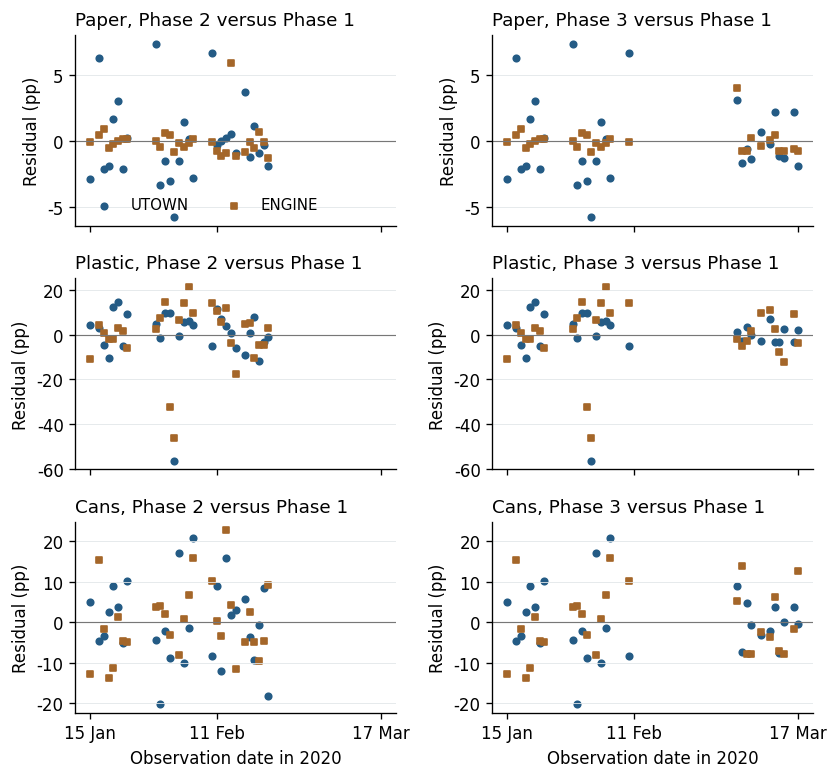

phase                    1            2            3      
area                ENGINE UTOWN ENGINE UTOWN ENGINE UTOWN
comparison material                                       
2          Cans       8.94 10.30   9.66 10.18    NaN   NaN
           Paper      0.43  3.74   2.04  1.48    NaN   NaN
           Plastic   16.50 15.62   9.09  7.23    NaN   NaN
3          Cans       8.94 10.30    NaN   NaN   8.27  5.11
           Paper      0.43  3.74    NaN   NaN   1.41  1.77
           Plastic   16.50 15.62    NaN   NaN   7.59  3.52

In [17]:
residual_rows = []
figure, axes = plt.subplots(3, 2, figsize=(7.1, 6.6), sharex=True)
for row_number, material in enumerate(material_columns):
    for column_number, phase in enumerate([2, 3]):
        axis = axes[row_number, column_number]
        selected = analysis_samples[(material, phase)].copy()
        selected["residual"] = fitted_models[(material, phase)].resid.to_numpy()

        for area in AREAS:
            area_data = selected[selected["area"] == area]
            axis.scatter(area_data["date"], area_data["residual"], s=15,
                         color=area_colours[area], marker=area_markers[area], label=area)

        # Record the spread of the residuals in each of the four area-phase groups.
        for (observed_phase, area), group in selected.groupby(["phase", "area"]):
            residual_rows.append({"comparison": phase, "material": material,
                                  "phase": observed_phase, "area": area,
                                  "residual_sd": group["residual"].std(ddof=1)})

        axis.axhline(0, color="#777777", linewidth=0.7)
        axis.set_title(f"{material}, Phase {phase} versus Phase 1", loc="left")
        axis.grid(axis="y", color="#E2E6E9", linewidth=0.5)
        axis.set_ylabel("Residual (pp)")
        format_date_axis(axis, ["2020-01-15", "2020-02-11", "2020-03-17"])

axes[0, 0].legend(ncol=2, frameon=False, fontsize=9)

# Give both panels of a material the same vertical scale.
for row_axes in axes:
    lower_limit = min(axis.get_ylim()[0] for axis in row_axes)
    upper_limit = max(axis.get_ylim()[1] for axis in row_axes)
    for axis in row_axes:
        axis.set_ylim(lower_limit, upper_limit)
for axis in axes[-1]:
    axis.set_xlabel("Observation date in 2020")
figure.tight_layout()
save_figure(figure, "residual_checks")
plt.show()

residual_spread = pd.DataFrame(residual_rows)
display(residual_spread.pivot(index=["comparison", "material"], columns=["phase", "area"],
                              values="residual_sd").round(2))

## 15. Repeat the calculation with other date choices

Lecture 5, slides 18-21, discusses unbalanced panels and sensitivity checks. We change one documented choice at a time and recalculate the same DiD. These are alternative comparisons, not additional trials.

- **All readings:** use each area's available dates, including dates without a partner.
- **Flagged dates excluded:** remove 2 February and the UTOWN 16 March record. We also try removing 12 March instead, since the repeated values do not tell us which record might be wrong.
- **Weekdays only:** examine the difference between the case's collection description and the recorded calendar dates.
- **Without 22 February:** remove the only observed recess date.
- **Recent baseline:** use Phase 1 from 27 January onward. This asks whether the comparison changes when the earlier baseline is removed.

The official NUS calendar places recess on 22 February to 1 March 2020. We use this information only for the date check. We do not select a main result according to which version gives a larger fall or a smaller p-value.

In [18]:
# Build the long data for one material, optionally keeping only dates with both areas.
def select_material_data(source_data, material, match_dates=True):
    column = material_columns[material]
    selected = (source_data[["date", "phase", "area", column]]
                .rename(columns={column: "contamination"})
                .dropna(subset=["contamination"]))
    if match_dates:
        wide = selected.pivot(index=["date", "phase"], columns="area", values="contamination")
        selected = to_long(wide.dropna(subset=AREAS).reset_index())
    return selected.sort_values(["date", "area"]).reset_index(drop=True)


# Return the records kept under one alternative choice of days.
def apply_variant(data, variant):
    if variant.startswith("Exclude 2 Feb"):
        march_date = "2020-03-16" if "16 Mar" in variant else "2020-03-12"
        removed = (data["date"] == "2020-02-02") | (
            (data["area"] == "UTOWN") & (data["date"] == march_date))
        return data.loc[~removed]
    if variant == "Weekdays only":
        return data.loc[~data["weekend"]]
    if variant == "Without 22 February":
        return data.loc[data["date"] != recess_start]
    if variant == "Recent baseline from 27 January":
        return data.loc[(data["phase"] != 1) | (data["date"] >= baseline_split)]
    # The main sample and the all-readings version keep every record.
    return data


variants = [
    "Main matched dates", "All available readings",
    "Exclude 2 Feb and UTOWN 16 Mar", "Exclude 2 Feb and UTOWN 12 Mar",
    "Weekdays only", "Without 22 February", "Recent baseline from 27 January",
]
sensitivity_rows = []
for variant in variants:
    variant_data = apply_variant(clean_data, variant)
    match_dates = variant != "All available readings"
    for phase in [2, 3]:
        for material in material_columns:
            selected = select_material_data(variant_data, material, match_dates)
            sensitivity_rows.append({"variant": variant, "phase": phase, "material": material,
                                     **calculate_changes(selected, 1, phase)})
sensitivity_results = pd.DataFrame(sensitivity_rows)

sensitivity_table = (
    sensitivity_results.pivot(index="variant", columns=["phase", "material"], values="did")
    .reindex(index=variants, columns=pd.MultiIndex.from_product([[2, 3], material_columns]))
)
display(sensitivity_table.round(2))

recent_can = (sensitivity_results
              .query("variant == 'Recent baseline from 27 January' and material == 'Cans'")
              .set_index("phase"))
display(Markdown(
    f"With the recent baseline, the can comparisons are {recent_can.loc[2, 'did']:.2f} pp for "
    f"openings and {recent_can.loc[3, 'did']:.2f} pp for banners. The change in size shows why "
    "the starting period matters. The versions are not upper and lower bounds on a causal "
    "effect. Date exclusions also cannot remove unmeasured changes in who uses each area."
))

2                    3              
                                Paper Plastic   Cans Paper Plastic  Cans
variant                                                                 
Main matched dates              -2.23    0.46 -15.02 -1.01    9.69 -7.24
All available readings          -2.52   -0.80 -14.96 -1.29    6.96 -6.87
Exclude 2 Feb and UTOWN 16 Mar  -2.52   -0.14 -15.02 -1.58   10.37 -7.79
Exclude 2 Feb and UTOWN 12 Mar  -2.52   -0.14 -15.02 -1.48    9.71 -6.99
Weekdays only                   -3.10    0.91 -12.99 -1.69    9.52 -8.28
Without 22 February             -2.17    0.89 -12.28 -1.01    9.69 -7.24
Recent baseline from 27 January -2.09    3.90  -9.50 -0.87   13.14 -1.72

With the recent baseline, the can comparisons are -9.50 pp for openings and -1.72 pp for banners. The change in size shows why the starting period matters. The versions are not upper and lower bounds on a causal effect. Date exclusions also cannot remove unmeasured changes in who uses each area.

## 16. Describe the switch from openings to banners

We compare Phase 3 with Phase 2 using the same four-mean calculation. This describes what changed between the periods. It does not isolate a banner effect: the openings were removed, a recess occurred in between, and earlier behaviour could carry forward.

In [19]:
switch_rows = []
for material in material_columns:
    result = calculate_changes(select_material_data(clean_data, material), 2, 3)
    # Phase 3 versus Phase 2 must equal the difference between the two main DiDs.
    expected = main_lookup.loc[(3, material), "did"] - main_lookup.loc[(2, material), "did"]
    assert np.isclose(result["did"], expected)
    switch_rows.append({"material": material, **result})
switch_results = pd.DataFrame(switch_rows)

display(switch_results[["material", "utown_change", "engine_change", "did"]].round(2))
display(Markdown("The area gap widens for all three materials after the switch. This is a "
                 "description of the two periods, with the limitations noted above."))

,material,utown_change,engine_change,did
0,Paper,0.69,-0.53,1.22
1,Plastic,12.67,3.44,9.24
2,Cans,3.96,-3.82,7.78


The area gap widens for all three materials after the switch. This is a description of the two periods, with the limitations noted above.

## 17. Summarise what the comparisons suggest

We use the estimated sizes together with the baseline and date checks. We avoid interpreting a p-value as a measure of the probability that the bins worked. We also avoid treating a result that is not statistically clear as evidence that the effect is exactly zero.

In [20]:
result_lookup = regression_results.set_index(["phase", "material"])
can_result = result_lookup.loc[(2, "Cans")]

display(Markdown(
    f"The openings period shows a relative can reduction of {can_openings.did:.2f} pp and a "
    f"smaller paper reduction of {main_lookup.loc[(2, 'Paper'), 'did']:.2f} pp. Plastic is close "
    f"to zero at {main_lookup.loc[(2, 'Plastic'), 'did']:+.2f} pp. Under the ordinary OLS "
    f"assumptions, the can interval is [{can_result.ci_low:.2f}, {can_result.ci_high:.2f}] pp.\n\n"
    "The banner-period comparisons are less favourable. They do not give clear evidence of an "
    "improvement. The earlier movement in the plastic and can gaps, uncertain model assumptions "
    "and calendar changes limit causal conclusions.\n\n"
    "The openings may be worth testing further, especially for cans. A larger trial could assign "
    "comparable sites to openings, banners or standard bins over the same weeks. It should record "
    "contamination, the amount collected and operating costs. This follows the randomized-trial "
    "ideas in Lecture 4. The present data do not measure total recycling, costs or effects "
    "outside NUS."
))

The openings period shows a relative can reduction of -15.02 pp and a smaller paper reduction of -2.23 pp. Plastic is close to zero at +0.46 pp. Under the ordinary OLS assumptions, the can interval is [-25.73, -4.32] pp.

The banner-period comparisons are less favourable. They do not give clear evidence of an improvement. The earlier movement in the plastic and can gaps, uncertain model assumptions and calendar changes limit causal conclusions.

The openings may be worth testing further, especially for cans. A larger trial could assign comparable sites to openings, banners or standard bins over the same weeks. It should record contamination, the amount collected and operating costs. This follows the randomized-trial ideas in Lecture 4. The present data do not measure total recycling, costs or effects outside NUS.

NUS reports that classes with more than 50 students moved online from 10 February 2020. This was one day before the openings period. UTOWN includes housing, while ENGINE has an academic focus. The change could have affected their users differently, but the supplied data do not measure that effect. Adding a simple calendar indicator would not by itself provide a credible way to separate it from the intervention.

Sources: [NUS 2020 review, page 2](https://nus.edu.sg/newshub/upr/202012/COVID-19%20Mitigation.pdf) and [NUS academic calendar 2019/2020, page 1](https://www.nus.edu.sg/registrar/docs/info/calendar/ay2019-2020.pdf). Dates provide context; no attendance or mobility values have been added to the outcome data.

## 18. Save the report tables and numbers

The following exports save CSV files at full precision, figures, and LaTeX tables and commands. They retain the connection between the calculations and the report's numerical results. This public repository includes the report PDF, not its LaTeX source. Running this notebook regenerates the exports in `assets/`; it does not update the supplied PDF.

In [21]:
# These formats match the numbers printed in the report.
def plain(value):
    return f"{value:.2f}"


def signed(value):
    return f"{value:+.2f}"


def p_text(value):
    return f"{value:.3f}"


# Write a table as LaTeX for the report to include.
def save_latex_table(table, filename, column_format=None):
    with warnings.catch_warnings():
        warnings.filterwarnings("ignore", message="In future versions.*", category=FutureWarning)
        latex = table.to_latex(index=False, escape=True, column_format=column_format)
    (assets_folder / filename).write_text(latex, encoding="utf-8")


# Save every results table at full precision as a CSV file.
export_tables = {
    "data_audit": audit_table, "area_phase_means": area_phase_summary,
    "matched_counts": sample_count_table, "unmatched_dates": unmatched_table,
    "baseline_checks": baseline_results, "arithmetic_results": arithmetic_results,
    "regression_results": regression_results, "sensitivity_results": sensitivity_results,
    "switch_results": switch_results, "residual_spread": residual_spread,
}
for name, table in export_tables.items():
    table.to_csv(assets_folder / f"{name}.csv", index=False)

# Build report Table 2, the main results.
main_report_rows = []
for row in regression_results.itertuples():
    means = main_lookup.loc[(row.phase, row.material)]
    main_report_rows.append({
        "Comparison": f"P{row.phase} versus P1",
        "Material": row.material,
        "Dates before/after": f"{int(means.utown_before_n)}/{int(means.utown_after_n)}",
        "DiD (pp)": signed(row.did),
        "95% interval (pp)": f"[{row.ci_low:.2f}, {row.ci_high:.2f}]",
        "p-value": p_text(row.p_value),
    })
save_latex_table(pd.DataFrame(main_report_rows), "main_results.tex", "lllrrr")
save_latex_table(audit_table, "data_audit.tex", "lr")
save_latex_table(sample_count_table, "matched_counts.tex", "lrrr")

# Build report Table 9, the averages using every recorded day.
phase_report = area_phase_summary.copy()
phase_report.columns = ["Phase", "Area", "Dates", "Paper (%)", "Plastic (%)", "Cans (%)",
                        "Can dates"]
for column in ["Paper (%)", "Plastic (%)", "Cans (%)"]:
    phase_report[column] = phase_report[column].map(plain)
save_latex_table(phase_report, "area_phase_means.tex", "rlrrrrr")

# Build report Tables 4 and 5, the four averages behind each DiD.
for phase in [2, 3]:
    four_means = arithmetic_results.loc[arithmetic_results["phase"] == phase, mean_columns].copy()
    four_means.columns = ["Material", "UTOWN before", "UTOWN after", "ENGINE before",
                          "ENGINE after", "DiD (pp)"]
    for column in four_means.columns[1:]:
        four_means[column] = four_means[column].map(plain)
    save_latex_table(four_means, f"four_means_phase{phase}.tex", "lrrrrr")

# Build report Table 6, the baseline trend and placebo checks.
baseline_report = pd.DataFrame({
    "Material": baseline_results["material"],
    "Gap trend (pp/week)": baseline_results["gap_change_per_week"].map(signed),
    "Trend p": baseline_results["trend_p"].map(p_text),
    "Placebo DiD (pp)": baseline_results["placebo_did"].map(signed),
    "Placebo p": baseline_results["placebo_p"].map(p_text),
})
save_latex_table(baseline_report, "baseline_checks.tex", "lrrrr")

# Build report Table 3, the estimates under alternative choices of days.
variant_labels = {
    "Main matched dates": "Main matched", "All available readings": "All readings",
    "Exclude 2 Feb and UTOWN 16 Mar": "Exclude 2 Feb / U 16 Mar",
    "Exclude 2 Feb and UTOWN 12 Mar": "Exclude 2 Feb / U 12 Mar",
    "Weekdays only": "Weekdays only", "Without 22 February": "Without 22 Feb",
    "Recent baseline from 27 January": "Recent baseline",
}
sensitivity_report = sensitivity_table.apply(lambda column: column.map(signed))
sensitivity_report.columns = [f"P{phase} {material}" for phase, material in sensitivity_table.columns]
sensitivity_report.insert(0, "Sample", [variant_labels[variant] for variant in sensitivity_table.index])
save_latex_table(sensitivity_report.reset_index(drop=True), "sensitivity.tex", "lrrrrrr")

# Build report Table 8, the banners period compared with the openings period.
switch_report = switch_results[["material", "utown_change", "engine_change", "did"]].copy()
switch_report.columns = ["Material", "UTOWN change (pp)", "ENGINE change (pp)",
                         "Relative change (pp)"]
for column in switch_report.columns[1:]:
    switch_report[column] = switch_report[column].map(signed)
save_latex_table(switch_report, "switch_results.tex", "lrrr")

# Build report Table 7, the can regression coefficients.
coefficient_report = coefficient_table.copy()
for column in ["Coefficient", "Standard error"]:
    coefficient_report[column] = coefficient_report[column].map(plain)
coefficient_report["p-value"] = coefficient_report["p-value"].map(p_text)
save_latex_table(coefficient_report, "can_coefficients.tex", "lrrr")

# Write LaTeX commands for the numbers quoted in the report text.
report_numbers = {
    "RawRows": str(len(raw_data)), "BlankRows": str(int(blank_rows.sum())),
    "RecordedRows": str(len(clean_data)),
    "MissingCans": str(int(clean_data["can_pct"].isna().sum())),
}
mean_labels = [("utown_before", "Ubefore"), ("utown_after", "Uafter"),
               ("engine_before", "Ebefore"), ("engine_after", "Eafter"),
               ("utown_change", "Uchange"), ("engine_change", "Echange")]
for phase in [2, 3]:
    for material in material_columns:
        means = main_lookup.loc[(phase, material)]
        regression = result_lookup.loc[(phase, material)]
        prefix = ("Openings" if phase == 2 else "Banners") + material
        report_numbers[prefix] = signed(means.did)
        for field, label in mean_labels:
            report_numbers[prefix + label] = plain(means[field])
        report_numbers[prefix + "Lower"] = plain(regression.ci_low)
        report_numbers[prefix + "Upper"] = plain(regression.ci_high)
        report_numbers[prefix + "Pvalue"] = p_text(regression.p_value)
switch_did = switch_results.set_index("material")["did"]
for material in material_columns:
    report_numbers[f"Baseline{material}Slope"] = signed(weekly_change[material])
    report_numbers[f"Switch{material}"] = signed(switch_did[material])
report_numbers["RecentOpeningsCans"] = signed(recent_can.loc[2, "did"])
report_numbers["RecentBannersCans"] = signed(recent_can.loc[3, "did"])
no_recess_can = sensitivity_results.query(
    "variant == 'Without 22 February' and phase == 2 and material == 'Cans'").iloc[0]
report_numbers["NoRecessOpeningsCans"] = signed(no_recess_can.did)

latex_commands = [f"\\newcommand{{\\{name}}}{{{value}}}" for name, value in report_numbers.items()]
(assets_folder / "results.tex").write_text("\n".join(latex_commands) + "\n", encoding="utf-8")

# Keep a record of the input, the method and the software versions used in this run.
result_record = {
    "input_file": "GP2Data.xls", "input_sha256": input_hash,
    "main_sample": "Same dates within each material; flagged readings retained",
    "regression": "contamination ~ treated + after + treated:after; ordinary OLS",
    "software": {"Python": platform.python_version(), "pandas": pd.__version__,
                 "numpy": np.__version__, "statsmodels": statsmodels.__version__,
                 "matplotlib": matplotlib.__version__},
    "report_numbers": report_numbers,
    "main_results": regression_results.to_dict("records"),
}
(assets_folder / "results.json").write_text(json.dumps(result_record, indent=2), encoding="utf-8")
print("Saved report tables, figures and numerical statements in assets.")

Saved report tables, figures and numerical statements in assets.


## 19. Check the completed calculations

These checks address the input and the main calculation. They verify that missing values were retained, the samples contain the expected recorded dates, the main arithmetic agrees with the regression, and the raw file was not changed. They do not test whether parallel trends is true.

In [22]:
# Check the size of the input and of each matched sample.
assert len(clean_data) == 85
assert int(blank_rows.sum()) == 170
assert clean_data["can_pct"].isna().sum() == 2
expected_counts = {"Paper": [18, 11, 11], "Plastic": [18, 11, 11], "Cans": [17, 11, 11]}
for material, counts in expected_counts.items():
    assert sample_count_table.set_index("Material").loc[material].tolist() == counts

# Check that the regression and the four-mean DiD agree, and that the sensitivity loop
# reproduces the main result in its main matched dates row.
assert len(regression_results) == 6
np.testing.assert_allclose(agreement_check["did_means"], agreement_check["did_ols"], atol=1e-10)
main_sensitivity = sensitivity_results.query("variant == 'Main matched dates'").merge(
    arithmetic_results, on=["phase", "material"], suffixes=("_check", "_main"))
np.testing.assert_allclose(main_sensitivity["did_check"], main_sensitivity["did_main"], atol=1e-10)

# The raw workbook is unchanged and the report files exist.
assert hashlib.sha256(data_path.read_bytes()).hexdigest() == input_hash
for filename in ["main_results.tex", "baseline_gaps.pdf", "did_combined.pdf"]:
    assert (assets_folder / filename).exists()
print("The data and arithmetic checks passed. The raw workbook is unchanged.")

The data and arithmetic checks passed. The raw workbook is unchanged.


## 20. Sources and contributions

The assignment brief and glossary define the outcomes and interventions. The case provides the setting and Exhibit 5. Lecture 5 supplies the DiD method, its assumptions and the idea of checking other samples. Basic Statistics and the Lecture 2 notebook supply ordinary regression and inference. Lecture 4 supports the suggestion of a randomized follow-up.

The final analysis draws on Aman's data preparation and baseline checks, Samuel's four-mean explanation, Ananya's simple interaction regression, Timothy's date-matching explanation and practical framing, and Yang's data audit and timeline. Results were recomputed from the shared raw file. The earlier contributors' files remain unchanged.

The final notebook uses the course model and simple date checks. Some methods explored in earlier work are outside this scope and are not carried into this notebook.